# Feature engineering và chọn đặc trưng liên quan đến Customer Churn

Notebook này lọc đặc trưng bằng **bằng chứng định lượng**, không chọn theo cảm tính. Mỗi biến được đánh giá bằng ba nguồn bằng chứng độc lập:

1. **Liên hệ đơn biến:** kiểm định thống kê đã hiệu chỉnh đa kiểm định (FDR) và effect size.
2. **Mutual information:** phát hiện cả quan hệ phi tuyến.
3. **Permutation importance trên tập validation:** đo mức giảm ROC-AUC khi xáo trộn một biến ngoài mẫu huấn luyện.

Một biến chỉ được chọn khi đạt ít nhất **2/3 nguồn bằng chứng**. Các biến số tương quan Spearman từ 0,85 trở lên được khử trùng lặp, giữ biến có bằng chứng tổng hợp mạnh hơn. `CustomerID` bị loại vì là mã định danh; `Churn` là biến đích.

> Lưu ý: liên hệ thống kê không tự động chứng minh quan hệ nhân quả. Ví dụ, nếu churn tăng sau tháng thứ 6 thì đó là bằng chứng về một điểm gãy theo tenure, nhưng chưa đủ để khẳng định nguyên nhân là hết ưu đãi khi dữ liệu không có biến về chương trình ưu đãi.

## Kết quả đã kiểm chứng trên tệp dữ liệu hiện tại

Với random seed 42, mô hình kiểm chứng đạt **ROC-AUC 0,6609** và **Average Precision 0,4254**, cao hơn baseline churn **0,2863**. Quy tắc 2/3 nguồn bằng chứng chọn 10/56 feature:

| Feature | Số nguồn bằng chứng | Minh chứng nổi bật |
|---|---:|---|
| `CurrentEquipmentDays` | 3/3 | effect score 0,1491; permutation importance 0,02905 |
| `TotalRecurringCharge` | 3/3 | effect score 0,0810; permutation 0,00421 |
| `CreditRating` | 3/3 | chênh churn giữa nhóm 10,08 điểm %; permutation 0,00754 |
| `MonthlyMinutes` | 3/3 | effect score 0,0783; permutation 0,00274 |
| `MadeCallToRetentionTeam` | 3/3 | chênh churn 15,25 điểm %; permutation 0,00337; có rủi ro xuất hiện muộn |
| `HandsetWebCapable` | 3/3 | chênh churn 10,49 điểm %; permutation 0,00137 |
| `ServiceArea` | 3/3 | Cramér's V hiệu chỉnh 0,0682; permutation 0,00096; cần lưu ý cardinality cao |
| `MonthsInService` | 2/3 | mutual information cao nhất 0,01350; permutation cao thứ hai 0,02095 |
| `PercChangeMinutes` | 2/3 | mutual information 0,00195; permutation 0,00955 |
| `RetentionCalls` | 2/3 | |SMD| 0,1195; permutation 0,00094; có rủi ro xuất hiện muộn |

Minh chứng về tenure: nhóm **0–6 tháng** có 727 khách và churn **19,53%**; nhóm **7–11 tháng** có 13.103 khách và churn **24,22%**. Chênh lệch **+4,69 điểm %**, risk ratio **1,24**, p = **0,00393**. Từ 7–11 sang 12–18 tháng, churn tăng thêm **8,75 điểm %** lên **32,98%** (risk ratio 1,36; p ≈ 1,47×10⁻⁵⁷). Tuy nhiên dữ liệu nhỏ nhất là 6 tháng, nên nhóm 0–6 thực tế chỉ đại diện tháng thứ 6; chưa có biến ưu đãi để kết luận nguyên nhân là hết ưu đãi.

Các cell bên dưới tái tạo toàn bộ kết quả và bảng bằng chứng này từ dữ liệu gốc.

In [13]:
from pathlib import Path
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import chi2_contingency, mannwhitneyu, norm
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
RANDOM_STATE = 42

## 1. Đọc dữ liệu sạch và xác định tập đặc trưng

Notebook ưu tiên `cell2cell_complete_cases.csv` đã loại các dòng có `NaN`. Chuỗi `Unknown` vẫn là một mức phân loại hợp lệ và không bị xem là dữ liệu thiếu.

In [14]:
data_candidates = [
    Path('../data/cell2cell_complete_cases.csv'),
    Path('data/cell2cell_complete_cases.csv'),
]
data_path = next((path.resolve() for path in data_candidates if path.exists()), None)
if data_path is None:
    raise FileNotFoundError('Không tìm thấy data/cell2cell_complete_cases.csv')

dataframe = pd.read_csv(data_path)
required_columns = {'CustomerID', 'Churn'}
if not required_columns.issubset(dataframe.columns):
    raise ValueError(f'Thiếu cột bắt buộc: {required_columns - set(dataframe.columns)}')
if dataframe.isna().any().any():
    raise ValueError('Tệp đầu vào vẫn còn NaN; hãy chạy notebook preprocessing trước.')

target_map = {'No': 0, 'Yes': 1}
if not set(dataframe['Churn'].unique()).issubset(target_map):
    raise ValueError(f'Giá trị Churn không hợp lệ: {dataframe["Churn"].unique()}')

y = dataframe['Churn'].map(target_map).astype('int8')
excluded_columns = ['CustomerID', 'Churn']
feature_columns = [
    column for column in dataframe.columns
    if column not in excluded_columns and dataframe[column].nunique(dropna=False) > 1
]
X = dataframe[feature_columns].copy()
categorical_features = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
numeric_features = [column for column in feature_columns if column not in categorical_features]

dataset_overview = pd.DataFrame({
    'metric': ['Số khách hàng', 'Số feature ứng viên', 'Feature số', 'Feature phân loại', 'Số churn', 'Tỷ lệ churn'],
    'value': [len(dataframe), len(feature_columns), len(numeric_features), len(categorical_features), int(y.sum()), f'{y.mean():.2%}'],
})
display(dataset_overview)
print(f'Dữ liệu: {data_path}')
print(f'MonthsInService quan sát từ {dataframe["MonthsInService"].min()} đến {dataframe["MonthsInService"].max()} tháng.')

,metric,value
0,Số khách hàng,49752
1,Số feature ứng viên,56
2,Feature số,34
3,Feature phân loại,22
4,Số churn,14245
5,Tỷ lệ churn,28.63%


Dữ liệu: D:\trực quan\data\cell2cell_complete_cases.csv
MonthsInService quan sát từ 6 đến 61 tháng.


In [15]:
# Tách validation trước khi tính bằng chứng để permutation importance được đánh giá ngoài mẫu.
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print(f'Train: {X_train.shape}; validation: {X_valid.shape}')
print(f'Churn rate - train: {y_train.mean():.2%}; validation: {y_valid.mean():.2%}')

Train: (37314, 56); validation: (12438, 56)
Churn rate - train: 28.63%; validation: 28.63%


## 2. Bằng chứng đơn biến

- Biến số: Mann–Whitney U, ROC-AUC đơn biến và standardized mean difference.
- Biến phân loại: Chi-square, Cramér's V và chênh lệch tỷ lệ churn giữa các nhóm đủ lớn.
- P-value được hiệu chỉnh Benjamini–Hochberg thành `q_value` để hạn chế phát hiện giả khi kiểm tra nhiều biến.

Cỡ mẫu lớn có thể làm p-value rất nhỏ dù tác động yếu, vì vậy notebook luôn yêu cầu cả **ý nghĩa thống kê lẫn effect size**.

In [16]:
def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    ranked = p_values[order]
    adjusted = ranked * len(ranked) / np.arange(1, len(ranked) + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    result = np.empty_like(adjusted)
    result[order] = np.clip(adjusted, 0, 1)
    return result


def corrected_cramers_v(contingency):
    chi2 = chi2_contingency(contingency, correction=False)[0]
    n = contingency.to_numpy().sum()
    rows, columns = contingency.shape
    if n <= 1:
        return 0.0
    phi2 = chi2 / n
    phi2_corrected = max(0.0, phi2 - ((columns - 1) * (rows - 1)) / (n - 1))
    rows_corrected = rows - ((rows - 1) ** 2) / (n - 1)
    columns_corrected = columns - ((columns - 1) ** 2) / (n - 1)
    denominator = min(rows_corrected - 1, columns_corrected - 1)
    return math.sqrt(phi2_corrected / denominator) if denominator > 0 else 0.0


def wilson_interval(successes, total, confidence=0.95):
    if total == 0:
        return np.nan, np.nan
    z = norm.ppf(1 - (1 - confidence) / 2)
    rate = successes / total
    denominator = 1 + z**2 / total
    centre = (rate + z**2 / (2 * total)) / denominator
    margin = z * math.sqrt(rate * (1 - rate) / total + z**2 / (4 * total**2)) / denominator
    return centre - margin, centre + margin


def two_proportion_test(successes_a, total_a, successes_b, total_b):
    rate_a = successes_a / total_a
    rate_b = successes_b / total_b
    pooled = (successes_a + successes_b) / (total_a + total_b)
    standard_error = math.sqrt(pooled * (1 - pooled) * (1 / total_a + 1 / total_b))
    z_score = (rate_b - rate_a) / standard_error
    p_value = 2 * norm.sf(abs(z_score))
    return rate_a, rate_b, rate_b - rate_a, rate_b / rate_a, z_score, p_value

In [17]:
univariate_rows = []

for feature in numeric_features:
    values = X_train[feature].astype(float)
    no_churn = values[y_train == 0]
    churn = values[y_train == 1]
    raw_auc = roc_auc_score(y_train, values)
    predictive_auc = max(raw_auc, 1 - raw_auc)
    pooled_std = math.sqrt((no_churn.var(ddof=1) + churn.var(ddof=1)) / 2)
    standardized_mean_difference = (churn.mean() - no_churn.mean()) / pooled_std if pooled_std > 0 else 0.0
    _, p_value = mannwhitneyu(no_churn, churn, alternative='two-sided')
    univariate_rows.append({
        'feature': feature,
        'feature_type': 'numeric',
        'p_value': p_value,
        'effect_score': 2 * (predictive_auc - 0.5),
        'roc_auc_strength': predictive_auc,
        'smd_abs': abs(standardized_mean_difference),
        'direction': 'cao hơn ở churn' if standardized_mean_difference > 0 else 'thấp hơn ở churn',
        'rate_gap_pp': np.nan,
        'levels': values.nunique(),
    })

minimum_group_size = max(30, int(0.002 * len(X_train)))
for feature in categorical_features:
    values = X_train[feature].astype(str)
    contingency = pd.crosstab(values, y_train)
    _, p_value, _, _ = chi2_contingency(contingency)
    group_summary = pd.DataFrame({'value': values, 'target': y_train}).groupby('value')['target'].agg(['size', 'mean'])
    supported_groups = group_summary[group_summary['size'] >= minimum_group_size]
    rate_gap = supported_groups['mean'].max() - supported_groups['mean'].min() if len(supported_groups) >= 2 else 0.0
    univariate_rows.append({
        'feature': feature,
        'feature_type': 'categorical',
        'p_value': p_value,
        'effect_score': corrected_cramers_v(contingency),
        'roc_auc_strength': np.nan,
        'smd_abs': np.nan,
        'direction': 'phụ thuộc mức phân loại',
        'rate_gap_pp': rate_gap * 100,
        'levels': values.nunique(),
    })

univariate_evidence = pd.DataFrame(univariate_rows)
univariate_evidence['q_value'] = benjamini_hochberg(univariate_evidence['p_value'])
univariate_evidence = univariate_evidence.sort_values(['effect_score', 'q_value'], ascending=[False, True])
display(univariate_evidence.head(20).round(4))

,feature,feature_type,p_value,effect_score,roc_auc_strength,smd_abs,direction,rate_gap_pp,levels,q_value
26,CurrentEquipmentDays,numeric,0.0,0.1491,0.5745,0.2298,cao hơn ở churn,NaN,1374,0.0
2,TotalRecurringCharge,numeric,0.0,0.0810,0.5405,0.1314,thấp hơn ở churn,NaN,197,0.0
1,MonthlyMinutes,numeric,0.0,0.0783,0.5392,0.1114,thấp hơn ở churn,NaN,2550,0.0
52,CreditRating,categorical,0.0,0.0714,NaN,NaN,phụ thuộc mức phân loại,10.0763,7,0.0
15,InboundCalls,numeric,0.0,0.0711,0.5356,0.0753,thấp hơn ở churn,NaN,431,0.0
37,HandsetWebCapable,categorical,0.0,0.0685,NaN,NaN,phụ thuộc mức phân loại,10.4935,2,0.0
17,OffPeakCallsInOut,numeric,0.0,0.0683,0.5342,0.0912,thấp hơn ở churn,NaN,1550,0.0
34,ServiceArea,categorical,0.0,0.0682,NaN,NaN,phụ thuộc mức phân loại,22.9117,719,0.0
11,CustomerCareCalls,numeric,0.0,0.0621,0.5310,0.0885,thấp hơn ở churn,NaN,174,0.0
51,MadeCallToRetentionTeam,categorical,0.0,0.0600,NaN,NaN,phụ thuộc mức phân loại,15.2498,2,0.0


## 3. Bằng chứng phi tuyến và ngoài mẫu

Mutual information được tính trên tập train sau khi chia biến số thành các quantile. Random Forest được huấn luyện trên train; permutation importance chỉ dùng validation. Vì vậy một biến chỉ có vẻ quan trọng trong train nhưng không giúp dự đoán khách hàng chưa thấy sẽ không dễ vượt qua tiêu chí chọn.

In [18]:
# Mã hóa rời rạc để mutual information có thể phát hiện quan hệ không đơn điệu.
X_mi = pd.DataFrame(index=X_train.index)
for feature in numeric_features:
    X_mi[feature] = pd.qcut(X_train[feature], q=10, labels=False, duplicates='drop').fillna(-1).astype(int)
for feature in categorical_features:
    X_mi[feature] = pd.factorize(X_train[feature].astype(str), sort=True)[0]

mi_values = mutual_info_classif(
    X_mi[feature_columns], y_train, discrete_features=True, random_state=RANDOM_STATE
)
mutual_information = pd.DataFrame({
    'feature': feature_columns,
    'mutual_info': mi_values,
}).sort_values('mutual_info', ascending=False)
display(mutual_information.head(20).round(5))

,feature,mutual_info
21,MonthsInService,0.01350
24,ServiceArea,0.01302
27,CurrentEquipmentDays,0.01130
2,TotalRecurringCharge,0.00320
52,CreditRating,0.00273
1,MonthlyMinutes,0.00243
32,HandsetWebCapable,0.00225
6,PercChangeMinutes,0.00195
17,OffPeakCallsInOut,0.00172
51,MadeCallToRetentionTeam,0.00168


In [19]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=25)),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features),
])
model = RandomForestClassifier(
    n_estimators=250,
    max_depth=14,
    min_samples_leaf=15,
    max_features='sqrt',
    class_weight='balanced_subsample',
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
model_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', model),
])
model_pipeline.fit(X_train, y_train)

validation_probability = model_pipeline.predict_proba(X_valid)[:, 1]
validation_auc = roc_auc_score(y_valid, validation_probability)
validation_ap = average_precision_score(y_valid, validation_probability)
print(f'Validation ROC-AUC: {validation_auc:.4f}')
print(f'Validation Average Precision: {validation_ap:.4f} (baseline = {y_valid.mean():.4f})')

# Lấy mẫu cố định để thời gian chạy permutation importance hợp lý và có thể tái lập.
permutation_index = X_valid.sample(n=min(6000, len(X_valid)), random_state=RANDOM_STATE).index
permutation_result = permutation_importance(
    model_pipeline,
    X_valid.loc[permutation_index],
    y_valid.loc[permutation_index],
    scoring='roc_auc',
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
permutation_evidence = pd.DataFrame({
    'feature': feature_columns,
    'permutation_mean': permutation_result.importances_mean,
    'permutation_std': permutation_result.importances_std,
}).sort_values('permutation_mean', ascending=False)
display(permutation_evidence.head(20).round(5))

Validation ROC-AUC: 0.6609
Validation Average Precision: 0.4254 (baseline = 0.2863)


,feature,permutation_mean,permutation_std
27,CurrentEquipmentDays,0.02905,0.00210
21,MonthsInService,0.02095,0.00181
6,PercChangeMinutes,0.00955,0.00199
52,CreditRating,0.00754,0.00154
4,OverageMinutes,0.00599,0.00059
2,TotalRecurringCharge,0.00421,0.00056
31,HandsetRefurbished,0.00387,0.00098
51,MadeCallToRetentionTeam,0.00337,0.00032
22,UniqueSubs,0.00329,0.00060
7,PercChangeRevenues,0.00284,0.00026


## 4. Quy tắc chọn feature có thể kiểm tra lại

Ba cờ bằng chứng được định nghĩa trước:

- `univariate_evidence`: q < 0,05 và effect đủ lớn (biến số: AUC ≥ 0,55 hoặc |SMD| ≥ 0,10; biến phân loại: Cramér's V ≥ 0,05 hoặc chênh churn ≥ 5 điểm %).
- `mi_evidence`: mutual information nằm trong tứ phân vị cao nhất và lớn hơn 0.
- `model_evidence`: permutation importance > 0,0005 ROC-AUC và trung bình trừ một độ lệch chuẩn vẫn dương.

Feature đạt ít nhất 2/3 cờ sẽ là ứng viên. Sau đó loại bớt biến số trùng thông tin nếu |Spearman| ≥ 0,85. Không giới hạn cứng số lượng feature nên kết quả không bị ép thành một con số tùy ý.

In [20]:
evidence = (
    univariate_evidence
    .merge(mutual_information, on='feature', how='left')
    .merge(permutation_evidence, on='feature', how='left')
)

numeric_effect = (evidence['roc_auc_strength'] >= 0.55) | (evidence['smd_abs'] >= 0.10)
categorical_effect = (evidence['effect_score'] >= 0.05) | (evidence['rate_gap_pp'] >= 5.0)
evidence['univariate_evidence'] = (
    (evidence['q_value'] < 0.05)
    & np.where(evidence['feature_type'].eq('numeric'), numeric_effect, categorical_effect)
)
mi_threshold = evidence['mutual_info'].quantile(0.75)
evidence['mi_evidence'] = (evidence['mutual_info'] >= mi_threshold) & (evidence['mutual_info'] > 0)
evidence['model_evidence'] = (
    (evidence['permutation_mean'] > 0.0005)
    & ((evidence['permutation_mean'] - evidence['permutation_std']) > 0)
)
evidence['evidence_count'] = evidence[
    ['univariate_evidence', 'mi_evidence', 'model_evidence']
].sum(axis=1)
evidence['evidence_strength'] = (
    0.35 * evidence['effect_score'].rank(pct=True)
    + 0.25 * evidence['mutual_info'].rank(pct=True)
    + 0.40 * evidence['permutation_mean'].rank(pct=True)
)
evidence['timing_risk'] = evidence['feature'].isin([
    'RetentionCalls', 'RetentionOffersAccepted', 'MadeCallToRetentionTeam'
])

candidates = evidence[evidence['evidence_count'] >= 2].sort_values(
    ['evidence_count', 'evidence_strength'], ascending=False
)

# Khử trùng lặp các biến số tương quan rất cao.
numeric_correlation = X_train[numeric_features].corr(method='spearman').abs()
selected_features = []
redundancy_rows = []
for feature in candidates['feature']:
    if feature in numeric_features:
        correlated_selected = [
            kept for kept in selected_features
            if kept in numeric_features and numeric_correlation.loc[feature, kept] >= 0.85
        ]
        if correlated_selected:
            redundancy_rows.append({
                'removed_feature': feature,
                'kept_feature': correlated_selected[0],
                'spearman_abs': numeric_correlation.loc[feature, correlated_selected[0]],
            })
            continue
    selected_features.append(feature)

evidence['selected'] = evidence['feature'].isin(selected_features)
final_evidence = evidence.sort_values(
    ['selected', 'evidence_count', 'evidence_strength'], ascending=False
)
display_columns = [
    'feature', 'feature_type', 'selected', 'evidence_count',
    'univariate_evidence', 'mi_evidence', 'model_evidence',
    'q_value', 'effect_score', 'roc_auc_strength', 'smd_abs', 'rate_gap_pp',
    'mutual_info', 'permutation_mean', 'permutation_std', 'timing_risk',
]
print(f'Ngưỡng mutual information (top 25%): {mi_threshold:.6f}')
print(f'Số feature ban đầu: {len(feature_columns)}')
print(f'Số ứng viên đạt ít nhất 2/3 bằng chứng: {len(candidates)}')
print(f'Số feature cuối cùng sau khử trùng lặp: {len(selected_features)}')
print('Feature được chọn:', selected_features)
display(final_evidence.loc[final_evidence['selected'], display_columns].round(5))

redundancy_log = pd.DataFrame(redundancy_rows)
if not redundancy_log.empty:
    print('Các feature bị loại do trùng thông tin:')
    display(redundancy_log.round(4))

timing_risk_selected = [feature for feature in selected_features if feature in ['RetentionCalls', 'RetentionOffersAccepted', 'MadeCallToRetentionTeam']]
if timing_risk_selected:
    print('CẢNH BÁO: các biến sau có thể chỉ xuất hiện muộn trong hành trình khách hàng:', timing_risk_selected)
    print('Chỉ dùng chúng cho mô hình dự báo nếu chắc chắn giá trị đã tồn tại tại thời điểm ra quyết định.')

Ngưỡng mutual information (top 25%): 0.001111
Số feature ban đầu: 56
Số ứng viên đạt ít nhất 2/3 bằng chứng: 10
Số feature cuối cùng sau khử trùng lặp: 10
Feature được chọn: ['CurrentEquipmentDays', 'TotalRecurringCharge', 'CreditRating', 'MonthlyMinutes', 'MadeCallToRetentionTeam', 'HandsetWebCapable', 'ServiceArea', 'MonthsInService', 'PercChangeMinutes', 'RetentionCalls']


,feature,feature_type,selected,evidence_count,univariate_evidence,mi_evidence,model_evidence,q_value,effect_score,roc_auc_strength,smd_abs,rate_gap_pp,mutual_info,permutation_mean,permutation_std,timing_risk
0,CurrentEquipmentDays,numeric,True,3,True,True,True,0.00000,0.14906,0.57453,0.22985,NaN,0.01130,0.02905,0.00210,False
1,TotalRecurringCharge,numeric,True,3,True,True,True,0.00000,0.08097,0.54048,0.13140,NaN,0.00320,0.00421,0.00056,False
3,CreditRating,categorical,True,3,True,True,True,0.00000,0.07136,NaN,NaN,10.07630,0.00273,0.00754,0.00154,False
2,MonthlyMinutes,numeric,True,3,True,True,True,0.00000,0.07833,0.53916,0.11137,NaN,0.00243,0.00274,0.00087,False
9,MadeCallToRetentionTeam,categorical,True,3,True,True,True,0.00000,0.06003,NaN,NaN,15.24978,0.00168,0.00337,0.00032,True
5,HandsetWebCapable,categorical,True,3,True,True,True,0.00000,0.06855,NaN,NaN,10.49353,0.00225,0.00137,0.00091,False
7,ServiceArea,categorical,True,3,True,True,True,0.00002,0.06817,NaN,NaN,22.91166,0.01302,0.00096,0.00032,False
16,MonthsInService,numeric,True,2,False,True,True,0.00000,0.05210,0.52605,0.04624,NaN,0.01350,0.02095,0.00181,False
10,PercChangeMinutes,numeric,True,2,False,True,True,0.00000,0.05967,0.52983,0.07183,NaN,0.00195,0.00955,0.00199,False
29,RetentionCalls,numeric,True,2,True,False,True,0.00000,0.02380,0.51190,0.11946,NaN,0.00000,0.00094,0.00016,True


CẢNH BÁO: các biến sau có thể chỉ xuất hiện muộn trong hành trình khách hàng: ['MadeCallToRetentionTeam', 'RetentionCalls']
Chỉ dùng chúng cho mô hình dự báo nếu chắc chắn giá trị đã tồn tại tại thời điểm ra quyết định.


### 4.1. Bộ feature ưu tiên cho phân tích dữ liệu

Mục tiêu phân tích khác với mục tiêu dự báo. Một feature có thể giúp mô hình dự đoán nhưng khó giải thích, không thể hành động hoặc chỉ xuất hiện sau khi khách hàng đã có ý định rời bỏ. Vì vậy notebook sử dụng một bộ **analysis features** riêng, dựa trên ba tiêu chí:

1. Được lặp lại trong nghiên cứu sử dụng Cell2Cell.
2. Có bằng chứng thống kê trên dữ liệu hiện tại.
3. Có ý nghĩa nghiệp vụ rõ ràng và có thể chuyển thành insight/hành động.

`ServiceArea` không được dùng làm feature phân tích chính vì có hàng trăm mã khu vực, khó diễn giải và dễ trở thành proxy địa lý. `RetentionCalls` và `MadeCallToRetentionTeam` được tách khỏi nhóm nguyên nhân chính vì có thể là phản ứng sau khi khách hàng đã thể hiện ý định churn.

In [ ]:
analysis_features = [
    # Thời gian và thiết bị
    'MonthsInService',
    'CurrentEquipmentDays',
    'HandsetWebCapable',
    # Chi phí và hồ sơ tín dụng
    'MonthlyRevenue',
    'TotalRecurringCharge',
    'CreditRating',
    # Mức sử dụng và sự thay đổi hành vi
    'MonthlyMinutes',
    'PercChangeMinutes',
    'PercChangeRevenues',
    'PeakCallsInOut',
]

analysis_feature_rationale = pd.DataFrame([
    ('MonthsInService', 'Tenure', 'Literature + dữ liệu', 'Quan hệ churn phi tuyến; kiểm tra các điểm gãy theo tháng'),
    ('CurrentEquipmentDays', 'Thiết bị', 'Literature + dữ liệu', 'Liên hệ số mạnh nhất với churn trong dữ liệu hiện tại'),
    ('HandsetWebCapable', 'Thiết bị', 'Dữ liệu hiện tại', "Cramér's V cao và dễ diễn giải theo khả năng thiết bị"),
    ('MonthlyRevenue', 'Tài chính', 'Literature', 'Phản ánh số tiền khách hàng thực chi hàng tháng'),
    ('TotalRecurringCharge', 'Tài chính', 'Literature + dữ liệu', 'Phí định kỳ, liên quan trực tiếp đến gánh nặng giá'),
    ('CreditRating', 'Tài chính', 'Dữ liệu hiện tại', "Cramér's V cao nhất trong nhóm categorical"),
    ('MonthlyMinutes', 'Sử dụng', 'Literature + dữ liệu', 'Mức độ sử dụng dịch vụ hàng tháng'),
    ('PercChangeMinutes', 'Thay đổi hành vi', 'Literature + dữ liệu', 'Phát hiện giảm/tăng sử dụng trước churn'),
    ('PercChangeRevenues', 'Thay đổi hành vi', 'Literature', 'Phát hiện thay đổi chi tiêu trước churn'),
    ('PeakCallsInOut', 'Sử dụng', 'Literature', 'Mức sử dụng trong giờ cao điểm'),
], columns=['feature', 'business_theme', 'evidence_source', 'analysis_value'])
display(analysis_feature_rationale)

excluded_from_primary_analysis = pd.DataFrame([
    ('CustomerID', 'Mã định danh, không phải hành vi khách hàng'),
    ('ServiceArea', 'Cardinality rất cao; khó diễn giải và có thể là proxy địa lý'),
    ('RetentionCalls', 'Có thể xuất hiện sau khi khách hàng đã có ý định churn'),
    ('MadeCallToRetentionTeam', 'Có nguy cơ reverse causality/timing leakage'),
], columns=['feature', 'reason'])
print('Các biến không dùng làm nguyên nhân phân tích chính:')
display(excluded_from_primary_analysis)

### 4.2. Heatmap mức liên hệ của từng feature với Churn

Không dùng Pearson cho mọi cột vì nhiều feature là chuỗi phân loại:

- Feature số dùng **point-biserial correlation** với `Churn` 0/1. Hệ số âm nghĩa là giá trị cao đi cùng churn thấp hơn; hệ số dương nghĩa là giá trị cao đi cùng churn cao hơn.
- Feature phân loại dùng **Cramér's V hiệu chỉnh**, nằm trong khoảng 0–1 và chỉ biểu diễn độ mạnh, không có chiều âm/dương.
- Dấu `★` đánh dấu feature thuộc bộ ưu tiên cho phân tích dữ liệu.

> Heatmap này đo liên hệ từng biến riêng lẻ, không chứng minh quan hệ nhân quả và có thể bỏ sót quan hệ phi tuyến. Vì vậy `MonthsInService` có thể có correlation tuyến tính yếu nhưng vẫn quan trọng theo mutual information và permutation importance.

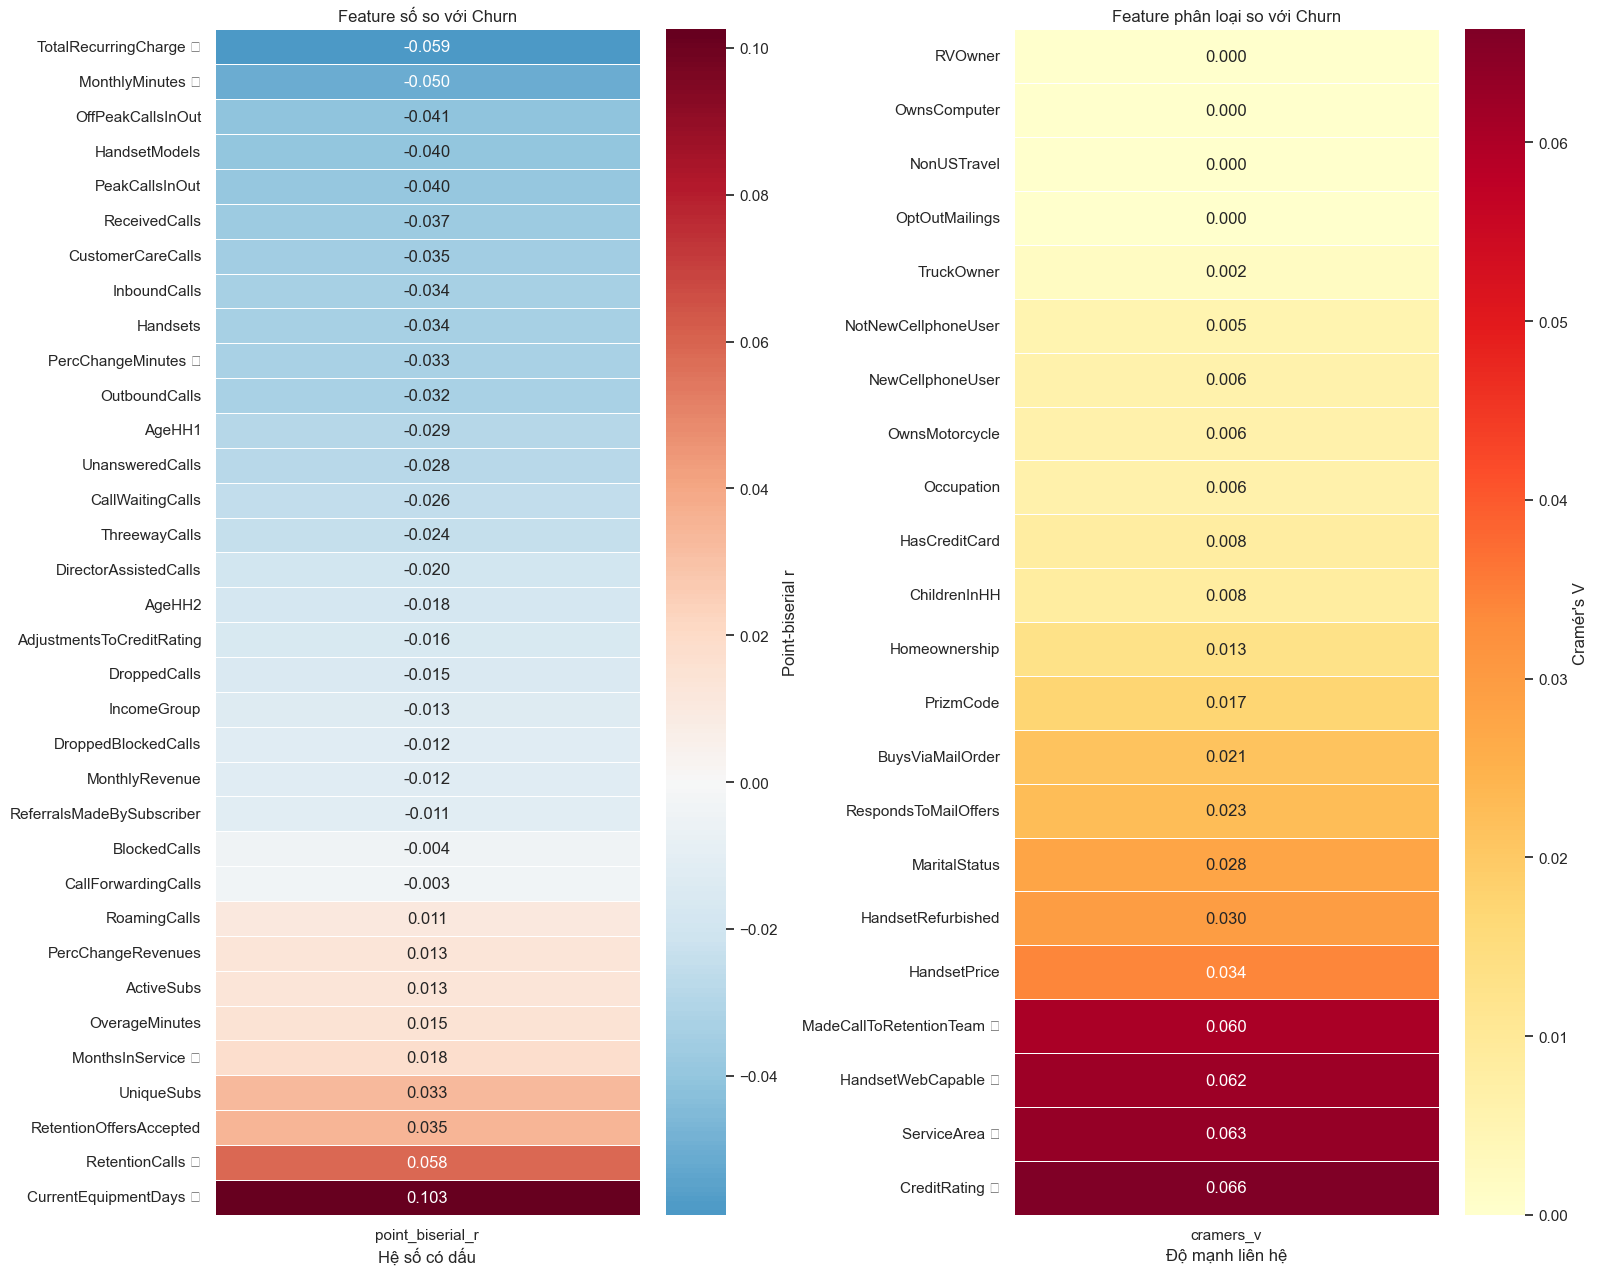

15 feature số liên hệ mạnh nhất với Churn:


,feature,point_biserial_r,absolute_strength,p_value,selected,q_value
26,CurrentEquipmentDays,0.10251,0.10251,0.0,True,0.0
2,TotalRecurringCharge,-0.05895,0.05895,0.0,True,0.0
29,RetentionCalls,0.05842,0.05842,0.0,True,0.0
1,MonthlyMinutes,-0.05016,0.05016,0.0,True,0.0
17,OffPeakCallsInOut,-0.04096,0.04096,0.0,False,0.0
25,HandsetModels,-0.04047,0.04047,0.0,False,0.0
16,PeakCallsInOut,-0.03953,0.03953,0.0,False,0.0
13,ReceivedCalls,-0.03710,0.03710,0.0,False,0.0
11,CustomerCareCalls,-0.03533,0.03533,0.0,False,0.0
30,RetentionOffersAccepted,0.03451,0.03451,0.0,False,0.0


15 feature phân loại liên hệ mạnh nhất với Churn:


,feature,cramers_v,p_value,selected,q_value
18,CreditRating,0.06631,0.00000,True,0.00000
0,ServiceArea,0.06340,0.00000,True,0.00000
3,HandsetWebCapable,0.06225,0.00000,True,0.00000
17,MadeCallToRetentionTeam,0.06041,0.00000,True,0.00000
16,HandsetPrice,0.03414,0.00000,False,0.00000
2,HandsetRefurbished,0.02969,0.00000,False,0.00000
21,MaritalStatus,0.02777,0.00000,False,0.00000
8,RespondsToMailOffers,0.02264,0.00000,False,0.00000
7,BuysViaMailOrder,0.02142,0.00000,False,0.00000
19,PrizmCode,0.01726,0.00048,False,0.00105


In [21]:
from scipy.stats import pointbiserialr

numeric_association_rows = []
for feature in numeric_features:
    correlation, p_value = pointbiserialr(y, dataframe[feature].astype(float))
    numeric_association_rows.append({
        'feature': feature,
        'point_biserial_r': correlation,
        'absolute_strength': abs(correlation),
        'p_value': p_value,
        'selected': feature in analysis_features,
    })
numeric_churn_association = pd.DataFrame(numeric_association_rows)
numeric_churn_association['q_value'] = benjamini_hochberg(
    numeric_churn_association['p_value']
)

categorical_association_rows = []
for feature in categorical_features:
    contingency = pd.crosstab(dataframe[feature].astype(str), y)
    _, p_value, _, _ = chi2_contingency(contingency)
    categorical_association_rows.append({
        'feature': feature,
        'cramers_v': corrected_cramers_v(contingency),
        'p_value': p_value,
        'selected': feature in analysis_features,
    })
categorical_churn_association = pd.DataFrame(categorical_association_rows)
categorical_churn_association['q_value'] = benjamini_hochberg(
    categorical_churn_association['p_value']
)

numeric_heatmap = numeric_churn_association.sort_values('point_biserial_r').copy()
categorical_heatmap = categorical_churn_association.sort_values('cramers_v').copy()
numeric_heatmap['display_feature'] = numeric_heatmap.apply(
    lambda row: f'{row["feature"]} ★' if row['selected'] else row['feature'], axis=1
)
categorical_heatmap['display_feature'] = categorical_heatmap.apply(
    lambda row: f'{row["feature"]} ★' if row['selected'] else row['feature'], axis=1
)

figure_height = max(12, 0.38 * max(len(numeric_heatmap), len(categorical_heatmap)))
fig, axes = plt.subplots(1, 2, figsize=(16, figure_height))

sns.heatmap(
    numeric_heatmap.set_index('display_feature')[['point_biserial_r']],
    cmap='RdBu_r', center=0, annot=True, fmt='.3f', linewidths=0.4,
    cbar_kws={'label': 'Point-biserial r'}, ax=axes[0],
)
axes[0].set_title('Feature số so với Churn')
axes[0].set_xlabel('Hệ số có dấu')
axes[0].set_ylabel('')

sns.heatmap(
    categorical_heatmap.set_index('display_feature')[['cramers_v']],
    cmap='YlOrRd', vmin=0, annot=True, fmt='.3f', linewidths=0.4,
    cbar_kws={'label': "Cramér's V"}, ax=axes[1],
)
axes[1].set_title('Feature phân loại so với Churn')
axes[1].set_xlabel('Độ mạnh liên hệ')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

numeric_top = (
    numeric_churn_association
    .sort_values('absolute_strength', ascending=False)
    .head(15)
)
categorical_top = (
    categorical_churn_association
    .sort_values('cramers_v', ascending=False)
    .head(15)
)
print('15 feature số liên hệ mạnh nhất với Churn:')
display(numeric_top.round(5))
print('15 feature phân loại liên hệ mạnh nhất với Churn:')
display(categorical_top.round(5))

## 5. Chọn độ sâu cho mô hình dự đoán không cần encoding thủ công

Phần này dùng **CatBoostClassifier**. CatBoost nhận trực tiếp tên các cột categorical và tự xử lý chúng trong quá trình huấn luyện, nên không cần `OneHotEncoder` hay `LabelEncoder`. Điều này phù hợp với `ServiceArea` có cardinality cao và tránh tạo hàng trăm cột giả.

Để chọn `depth`:

- Chỉ dùng tập train trước đó và tách thêm một tập `depth_validation` nội bộ.
- Thử depth từ 3 đến 10 với cùng learning rate và giới hạn iterations.
- Vẽ Train Log Loss và Validation Log Loss theo depth.
- Chọn depth có **Validation Log Loss nhỏ nhất**; khoảng cách giữa validation loss và train loss giúp nhận biết overfitting.

> Việc chuyển cột categorical sang kiểu chuỗi chỉ là khai báo kiểu dữ liệu cho CatBoost, không phải mã hóa giá trị.

**Kết quả đã kiểm chứng trên dữ liệu hiện tại:** depth **9** có validation Log Loss thấp nhất (**0,56356**) và ROC-AUC **0,66328** tại iteration 243. Depth 10 có train loss thấp hơn nhưng validation loss tăng lên 0,56561 và overfit gap lớn hơn, nên không được chọn. Khi huấn luyện lại depth 9 trên toàn bộ train, tập validation bên ngoài đạt Log Loss **0,56262**, ROC-AUC **0,66530** và Average Precision **0,43971**.

,depth,best_iteration,train_log_loss,validation_log_loss,overfit_gap,validation_roc_auc
0,3,249,0.56115,0.56724,0.00610,0.65752
1,4,250,0.55710,0.56548,0.00838,0.66101
2,5,249,0.55523,0.56492,0.00969,0.66230
3,6,250,0.54938,0.56462,0.01525,0.66150
4,7,249,0.54418,0.56431,0.02013,0.66206
5,8,250,0.53948,0.56411,0.02463,0.66233
6,9,243,0.53386,0.56356,0.02970,0.66328
7,10,201,0.53274,0.56561,0.03287,0.65866


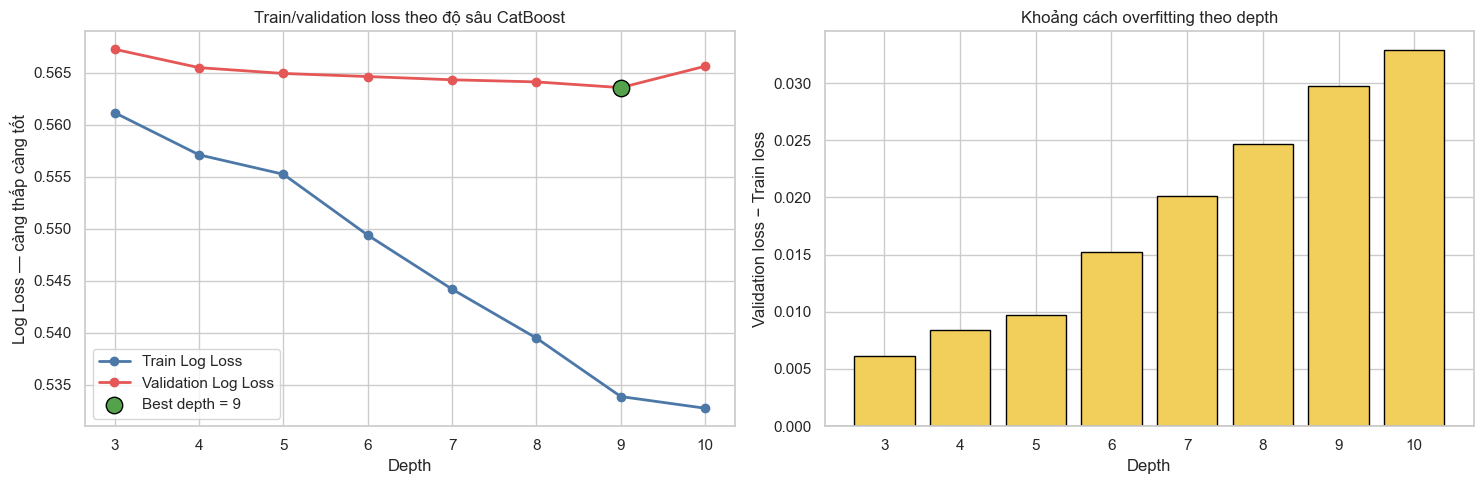

Depth tốt nhất theo validation Log Loss: 9
Best iteration tại depth này: 243
Validation Log Loss: 0.56356
Validation ROC-AUC: 0.66328


In [22]:
from catboost import CatBoostClassifier
from sklearn.metrics import log_loss

catboost_categorical_features = [
    feature for feature in selected_features if feature in categorical_features
]
X_catboost = X_train[selected_features].copy()
for feature in catboost_categorical_features:
    X_catboost[feature] = X_catboost[feature].astype(str)

X_depth_train, X_depth_valid, y_depth_train, y_depth_valid = train_test_split(
    X_catboost,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=RANDOM_STATE,
)

depth_candidates = [3, 4, 5, 6, 7, 8, 9, 10]
depth_results = []
depth_models = {}

for depth in depth_candidates:
    depth_model = CatBoostClassifier(
        iterations=250,
        depth=depth,
        learning_rate=0.05,
        loss_function='Logloss',
        eval_metric='Logloss',
        l2_leaf_reg=5,
        random_seed=RANDOM_STATE,
        allow_writing_files=False,
        verbose=False,
        thread_count=-1,
    )
    depth_model.fit(
        X_depth_train,
        y_depth_train,
        cat_features=catboost_categorical_features,
        eval_set=(X_depth_valid, y_depth_valid),
        early_stopping_rounds=30,
        use_best_model=True,
        verbose=False,
    )

    train_probability = depth_model.predict_proba(X_depth_train)[:, 1]
    valid_probability = depth_model.predict_proba(X_depth_valid)[:, 1]
    train_loss = log_loss(y_depth_train, train_probability)
    valid_loss = log_loss(y_depth_valid, valid_probability)
    valid_auc = roc_auc_score(y_depth_valid, valid_probability)
    best_iteration = depth_model.get_best_iteration() + 1

    depth_results.append({
        'depth': depth,
        'best_iteration': best_iteration,
        'train_log_loss': train_loss,
        'validation_log_loss': valid_loss,
        'overfit_gap': valid_loss - train_loss,
        'validation_roc_auc': valid_auc,
    })
    depth_models[depth] = depth_model

depth_results = pd.DataFrame(depth_results).sort_values('depth').reset_index(drop=True)
best_depth_row = depth_results.loc[depth_results['validation_log_loss'].idxmin()]
best_depth = int(best_depth_row['depth'])
best_depth_iterations = int(best_depth_row['best_iteration'])
display(depth_results.round(5))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(
    depth_results['depth'], depth_results['train_log_loss'],
    marker='o', linewidth=2, label='Train Log Loss', color='#4C78A8',
)
axes[0].plot(
    depth_results['depth'], depth_results['validation_log_loss'],
    marker='o', linewidth=2, label='Validation Log Loss', color='#E45756',
)
axes[0].scatter(
    [best_depth], [best_depth_row['validation_log_loss']],
    s=140, color='#54A24B', edgecolor='black', zorder=5, label=f'Best depth = {best_depth}',
)
axes[0].set_xticks(depth_candidates)
axes[0].set_xlabel('Depth')
axes[0].set_ylabel('Log Loss — càng thấp càng tốt')
axes[0].set_title('Train/validation loss theo độ sâu CatBoost')
axes[0].legend()

axes[1].bar(
    depth_results['depth'], depth_results['overfit_gap'], color='#F2CF5B', edgecolor='black'
)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_xticks(depth_candidates)
axes[1].set_xlabel('Depth')
axes[1].set_ylabel('Validation loss − Train loss')
axes[1].set_title('Khoảng cách overfitting theo depth')
plt.tight_layout()
plt.show()

print(f'Depth tốt nhất theo validation Log Loss: {best_depth}')
print(f'Best iteration tại depth này: {best_depth_iterations}')
print(f'Validation Log Loss: {best_depth_row["validation_log_loss"]:.5f}')
print(f'Validation ROC-AUC: {best_depth_row["validation_roc_auc"]:.5f}')

In [23]:
# Huấn luyện lại depth đã chọn trên toàn bộ train và đánh giá trên validation bên ngoài.
X_catboost_train = X_train[selected_features].copy()
X_catboost_valid = X_valid[selected_features].copy()
for feature in catboost_categorical_features:
    X_catboost_train[feature] = X_catboost_train[feature].astype(str)
    X_catboost_valid[feature] = X_catboost_valid[feature].astype(str)

best_catboost_model = CatBoostClassifier(
    iterations=best_depth_iterations,
    depth=best_depth,
    learning_rate=0.05,
    loss_function='Logloss',
    eval_metric='Logloss',
    l2_leaf_reg=5,
    random_seed=RANDOM_STATE,
    allow_writing_files=False,
    verbose=False,
    thread_count=-1,
 )
best_catboost_model.fit(
    X_catboost_train, y_train, cat_features=catboost_categorical_features, verbose=False
)
final_probability = best_catboost_model.predict_proba(X_catboost_valid)[:, 1]
final_catboost_metrics = pd.DataFrame({
    'metric': ['Log Loss', 'ROC-AUC', 'Average Precision'],
    'value': [
        log_loss(y_valid, final_probability),
        roc_auc_score(y_valid, final_probability),
        average_precision_score(y_valid, final_probability),
    ],
})
display(final_catboost_metrics.round(5))

catboost_importance = pd.DataFrame({
    'feature': selected_features,
    'catboost_importance': best_catboost_model.get_feature_importance(),
}).sort_values('catboost_importance', ascending=False)
display(catboost_importance.round(4))

,metric,value
0,Log Loss,0.56262
1,ROC-AUC,0.66530
2,Average Precision,0.43971


,feature,catboost_importance
7,MonthsInService,16.1092
6,ServiceArea,15.4443
8,PercChangeMinutes,14.1788
0,CurrentEquipmentDays,13.3275
3,MonthlyMinutes,12.0530
2,CreditRating,12.0300
1,TotalRecurringCharge,11.0785
5,HandsetWebCapable,2.7494
4,MadeCallToRetentionTeam,1.7364
9,RetentionCalls,1.2928


### 5.1. Đánh giá bộ feature hiện tại so với feature từ bài báo

Bốn bộ feature được đánh giá bằng cùng một cấu hình CatBoost (`depth=6`, 150 iterations) và cùng 5 fold Stratified Cross-Validation. Cấu hình cố định giúp phép so sánh tập trung vào chất lượng feature, không để một bộ được hưởng lợi từ tuning riêng.

- **Current 10:** bộ feature do quy tắc 2/3 bằng chứng trong notebook chọn.
- **Literature 8:** các biến lặp lại trong nghiên cứu Cell2Cell đã khảo sát.
- **Overlap core 5:** phần giao nhau giữa hai bộ trên.
- **All 56:** baseline dùng toàn bộ feature hợp lệ.

ROC-AUC và Average Precision càng cao càng tốt; Log Loss càng thấp càng tốt. Kết quả được tính từ out-of-fold prediction, nghĩa là mỗi khách hàng chỉ được dự đoán bởi mô hình chưa nhìn thấy khách hàng đó khi huấn luyện.

**Kết quả đã kiểm chứng trên dữ liệu hiện tại:**

| Bộ feature | ROC-AUC | Average Precision | Log Loss | Tổng thời gian 5 fold |
|---|---:|---:|---:|---:|
| All 56 | **0,67060** | **0,44043** | **0,56276** | 44,75 giây |
| Current 10 | 0,65854 | 0,43018 | 0,56625 | 27,43 giây |
| Literature 8 | 0,65708 | 0,42909 | 0,56659 | **3,29 giây** |
| Overlap core 5 | 0,65197 | 0,42256 | 0,56840 | 3,16 giây |

Bộ 10 chỉ hơn bộ 8 khoảng 0,00149 ROC-AUC và 0,00104 Average Precision. Bootstrap 95% CI lần lượt là [−0,00127; 0,00397] và [−0,00290; 0,00499], đều chứa 0: **chưa có bằng chứng bộ 10 tốt hơn bộ 8**. Bộ 8 huấn luyện nhanh hơn khoảng 8 lần vì không chứa categorical cardinality cao như `ServiceArea`. Nếu ưu tiên dự báo, toàn bộ 56 feature đang tốt nhất; nếu ưu tiên mô hình gọn và nhanh, bộ 8 từ tài liệu hợp lý hơn bộ 10 hiện tại.

In [ ]:
from time import perf_counter
from catboost import CatBoostClassifier
from sklearn.metrics import log_loss
from sklearn.model_selection import StratifiedKFold

literature_features = [
    'CurrentEquipmentDays',
    'MonthlyMinutes',
    'PercChangeMinutes',
    'MonthsInService',
    'MonthlyRevenue',
    'TotalRecurringCharge',
    'PeakCallsInOut',
    'PercChangeRevenues',
]
overlap_features = [feature for feature in literature_features if feature in selected_features]
feature_sets = {
    f'Current evidence-based ({len(selected_features)})': selected_features,
    f'Literature consensus ({len(literature_features)})': literature_features,
    f'Overlap core ({len(overlap_features)})': overlap_features,
    f'All eligible ({len(feature_columns)})': feature_columns,
}

cross_validator = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_rows = []
out_of_fold_probabilities = {}

for set_name, features in feature_sets.items():
    categorical_in_set = [feature for feature in features if feature in categorical_features]
    model_data = X[features].copy()
    for feature in categorical_in_set:
        model_data[feature] = model_data[feature].astype(str)

    oof_probability = np.zeros(len(model_data), dtype=float)
    for fold_number, (train_index, valid_index) in enumerate(
        cross_validator.split(model_data, y), start=1
    ):
        fold_model = CatBoostClassifier(
            iterations=150,
            depth=6,
            learning_rate=0.05,
            loss_function='Logloss',
            eval_metric='Logloss',
            l2_leaf_reg=5,
            random_seed=RANDOM_STATE + fold_number,
            allow_writing_files=False,
            verbose=False,
            thread_count=-1,
        )
        start_time = perf_counter()
        fold_model.fit(
            model_data.iloc[train_index],
            y.iloc[train_index],
            cat_features=categorical_in_set,
            verbose=False,
        )
        training_seconds = perf_counter() - start_time
        fold_probability = fold_model.predict_proba(model_data.iloc[valid_index])[:, 1]
        oof_probability[valid_index] = fold_probability
        fold_target = y.iloc[valid_index]
        fold_rows.append({
            'feature_set': set_name,
            'feature_count': len(features),
            'fold': fold_number,
            'roc_auc': roc_auc_score(fold_target, fold_probability),
            'average_precision': average_precision_score(fold_target, fold_probability),
            'log_loss': log_loss(fold_target, fold_probability),
            'training_seconds': training_seconds,
        })
    out_of_fold_probabilities[set_name] = oof_probability

feature_set_fold_results = pd.DataFrame(fold_rows)
feature_set_results = []
for set_name, features in feature_sets.items():
    probability = out_of_fold_probabilities[set_name]
    fold_subset = feature_set_fold_results[feature_set_fold_results['feature_set'].eq(set_name)]
    feature_set_results.append({
        'feature_set': set_name,
        'feature_count': len(features),
        'oof_roc_auc': roc_auc_score(y, probability),
        'roc_auc_fold_std': fold_subset['roc_auc'].std(ddof=1),
        'oof_average_precision': average_precision_score(y, probability),
        'average_precision_fold_std': fold_subset['average_precision'].std(ddof=1),
        'oof_log_loss': log_loss(y, probability),
        'log_loss_fold_std': fold_subset['log_loss'].std(ddof=1),
        'total_training_seconds': fold_subset['training_seconds'].sum(),
    })
feature_set_comparison = pd.DataFrame(feature_set_results).sort_values(
    ['oof_log_loss', 'oof_roc_auc'], ascending=[True, False]
)
display(feature_set_comparison.round(5))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
plot_order = feature_set_comparison['feature_set'].tolist()
metric_plot_settings = [
    ('oof_roc_auc', 'ROC-AUC — cao hơn tốt hơn', '#4C78A8'),
    ('oof_average_precision', 'Average Precision — cao hơn tốt hơn', '#54A24B'),
    ('oof_log_loss', 'Log Loss — thấp hơn tốt hơn', '#E45756'),
]
for axis, (metric, title, color) in zip(axes, metric_plot_settings):
    sns.barplot(
        data=feature_set_comparison, x=metric, y='feature_set',
        order=plot_order, color=color, ax=axis,
    )
    axis.set_title(title)
    axis.set_xlabel('')
    axis.set_ylabel('')
    for container in axis.containers:
        axis.bar_label(container, fmt='%.4f', padding=3)
plt.tight_layout()
plt.show()

current_name = next(name for name in feature_sets if name.startswith('Current evidence-based'))
literature_name = next(name for name in feature_sets if name.startswith('Literature consensus'))
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_rows = []
for _ in range(500):
    sample_index = rng.integers(0, len(y), len(y))
    sampled_target = y.iloc[sample_index]
    if sampled_target.nunique() < 2:
        continue
    current_probability = out_of_fold_probabilities[current_name][sample_index]
    literature_probability = out_of_fold_probabilities[literature_name][sample_index]
    bootstrap_rows.append({
        'roc_auc_difference_current_minus_literature': (
            roc_auc_score(sampled_target, current_probability)
            - roc_auc_score(sampled_target, literature_probability)
        ),
        'average_precision_difference_current_minus_literature': (
            average_precision_score(sampled_target, current_probability)
            - average_precision_score(sampled_target, literature_probability)
        ),
        'log_loss_difference_current_minus_literature': (
            log_loss(sampled_target, current_probability)
            - log_loss(sampled_target, literature_probability)
        ),
    })
bootstrap_differences = pd.DataFrame(bootstrap_rows)
bootstrap_summary = pd.DataFrame({
    'metric_difference': bootstrap_differences.columns,
    'mean_difference': bootstrap_differences.mean().values,
    'ci_2.5%': bootstrap_differences.quantile(0.025).values,
    'ci_97.5%': bootstrap_differences.quantile(0.975).values,
})
print('Bootstrap 95% CI: Current 10 trừ Literature 8')
print('ROC-AUC/AP dương ủng hộ Current 10; Log Loss âm ủng hộ Current 10.')
display(bootstrap_summary.round(5))

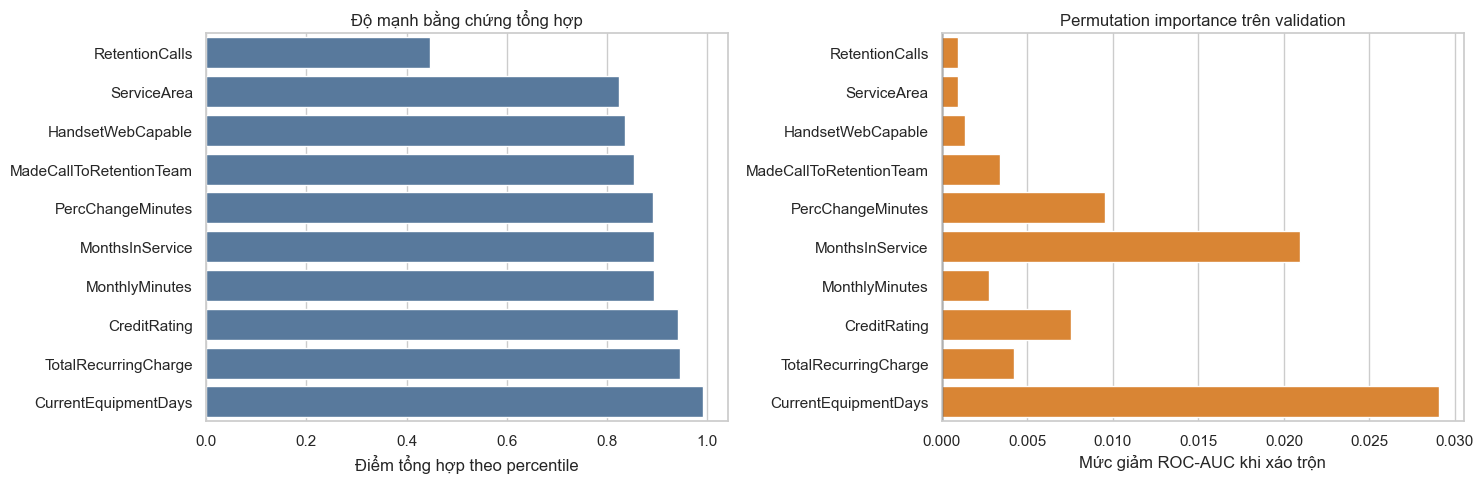

In [24]:
selected_plot = (
    final_evidence[final_evidence['selected']]
    .sort_values('evidence_strength', ascending=True)
)
fig_height = max(5, 0.42 * len(selected_plot))
fig, axes = plt.subplots(1, 2, figsize=(15, fig_height))

sns.barplot(data=selected_plot, x='evidence_strength', y='feature', color='#4C78A8', ax=axes[0])
axes[0].set_title('Độ mạnh bằng chứng tổng hợp')
axes[0].set_xlabel('Điểm tổng hợp theo percentile')
axes[0].set_ylabel('')

sns.barplot(data=selected_plot, x='permutation_mean', y='feature', color='#F58518', ax=axes[1])
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Permutation importance trên validation')
axes[1].set_xlabel('Mức giảm ROC-AUC khi xáo trộn')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

## 6. Kiểm chứng giả thuyết về thời gian sử dụng

Phần này không chỉ vẽ tỷ lệ churn mà còn hiển thị cỡ mẫu, khoảng tin cậy Wilson 95%, chênh lệch điểm phần trăm, risk ratio và p-value giữa các khoảng tenure liền kề. Nhóm có cỡ mẫu quá nhỏ phải được diễn giải thận trọng.

,tenure_band,customers,churners,churn_rate,ci_low,ci_high,churn_rate_pct
0,0–6,727,142,0.1953,0.1681,0.2257,19.5323
1,7–11,13103,3174,0.2422,0.2350,0.2496,24.2235
2,12–18,14335,4727,0.3298,0.3221,0.3375,32.9752
3,19–24,9330,2750,0.2947,0.2856,0.3041,29.4748
4,25–36,9451,2693,0.2849,0.2759,0.2941,28.4943
5,37–60,2805,758,0.2702,0.2541,0.2870,27.0232
6,61+,1,1,1.0000,0.2065,1.0000,100.0000


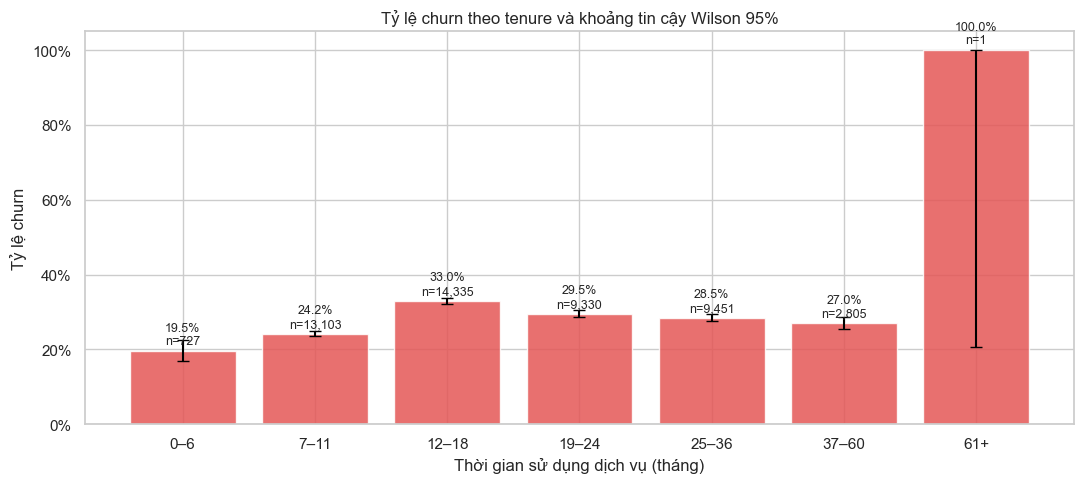

,comparison,rate_before,rate_after,difference_pp,risk_ratio,z_score,p_value
0,0–6 → 7–11,0.19532,0.24223,4.69114,1.24017,2.88370,0.00393
1,7–11 → 12–18,0.24223,0.32975,8.75178,1.36129,15.99141,0.00000


LƯU Ý DỮ LIỆU: MonthsInService nhỏ nhất = 6, nên nhóm 0–6 chỉ có quan sát tại tháng thứ 6.
Từ nhóm 0–6 sang 7–11 tháng, churn thay đổi +4.69 điểm %, risk ratio = 1.24, p = 0.00393.
Kết luận hợp lệ: có điểm tăng churn theo tenure nếu p < 0,05 và khoảng tin cậy/cỡ mẫu phù hợp.
Chưa thể kết luận nguyên nhân là hết ưu đãi vì dữ liệu hiện tại không có biến ngày hết ưu đãi, loại ưu đãi hoặc giá trước/sau ưu đãi.


In [25]:
tenure_bins = [-np.inf, 6, 11, 18, 24, 36, 60, np.inf]
tenure_labels = ['0–6', '7–11', '12–18', '19–24', '25–36', '37–60', '61+']
tenure_data = dataframe[['MonthsInService', 'Churn']].copy()
tenure_data['churn_flag'] = tenure_data['Churn'].eq('Yes').astype(int)
tenure_data['tenure_band'] = pd.cut(
    tenure_data['MonthsInService'], bins=tenure_bins, labels=tenure_labels
)
tenure_summary = (
    tenure_data.groupby('tenure_band', observed=False)['churn_flag']
    .agg(customers='size', churners='sum', churn_rate='mean')
    .reset_index()
)
intervals = tenure_summary.apply(
    lambda row: wilson_interval(row['churners'], row['customers']), axis=1
)
tenure_summary['ci_low'] = [interval[0] for interval in intervals]
tenure_summary['ci_high'] = [interval[1] for interval in intervals]
tenure_summary['churn_rate_pct'] = tenure_summary['churn_rate'] * 100
display(tenure_summary.round(4))

fig, ax = plt.subplots(figsize=(11, 5))
x_positions = np.arange(len(tenure_summary))
error_bars = np.vstack([
    tenure_summary['churn_rate'] - tenure_summary['ci_low'],
    tenure_summary['ci_high'] - tenure_summary['churn_rate'],
])
ax.bar(x_positions, tenure_summary['churn_rate'], color='#E45756', alpha=0.85)
ax.errorbar(x_positions, tenure_summary['churn_rate'], yerr=error_bars, fmt='none', color='black', capsize=4)
ax.set_xticks(x_positions, tenure_summary['tenure_band'].astype(str))
ax.set_ylabel('Tỷ lệ churn')
ax.set_xlabel('Thời gian sử dụng dịch vụ (tháng)')
ax.set_title('Tỷ lệ churn theo tenure và khoảng tin cậy Wilson 95%')
ax.yaxis.set_major_formatter(lambda value, position: f'{value:.0%}')
for position, row in tenure_summary.iterrows():
    ax.text(position, row['churn_rate'] + 0.018, f'{row["churn_rate"]:.1%}\nn={int(row["customers"]):,}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()

comparison_pairs = [('0–6', '7–11'), ('7–11', '12–18')]
comparison_rows = []
summary_by_band = tenure_summary.set_index(tenure_summary['tenure_band'].astype(str))
for band_a, band_b in comparison_pairs:
    row_a = summary_by_band.loc[band_a]
    row_b = summary_by_band.loc[band_b]
    rate_a, rate_b, difference, risk_ratio, z_score, p_value = two_proportion_test(
        row_a['churners'], row_a['customers'], row_b['churners'], row_b['customers']
    )
    comparison_rows.append({
        'comparison': f'{band_a} → {band_b}',
        'rate_before': rate_a,
        'rate_after': rate_b,
        'difference_pp': difference * 100,
        'risk_ratio': risk_ratio,
        'z_score': z_score,
        'p_value': p_value,
    })
tenure_comparisons = pd.DataFrame(comparison_rows)
display(tenure_comparisons.round(5))

print(f'LƯU Ý DỮ LIỆU: MonthsInService nhỏ nhất = {dataframe["MonthsInService"].min()}, nên nhóm 0–6 chỉ có quan sát tại tháng thứ 6.')
first_comparison = tenure_comparisons.iloc[0]
print(
    f'Từ nhóm 0–6 sang 7–11 tháng, churn thay đổi {first_comparison["difference_pp"]:+.2f} điểm %, '
    f'risk ratio = {first_comparison["risk_ratio"]:.2f}, p = {first_comparison["p_value"]:.4g}.'
)
print('Kết luận hợp lệ: có điểm tăng churn theo tenure nếu p < 0,05 và khoảng tin cậy/cỡ mẫu phù hợp.')
print('Chưa thể kết luận nguyên nhân là hết ưu đãi vì dữ liệu hiện tại không có biến ngày hết ưu đãi, loại ưu đãi hoặc giá trước/sau ưu đãi.')

## 7. Hồ sơ churn của các feature được chọn

Bảng dưới chia biến số thành 5 quantile; biến phân loại giữ 8 nhóm phổ biến nhất và gộp phần còn lại. `lift_vs_overall` cho biết tỷ lệ churn của nhóm cao/thấp hơn mức chung bao nhiêu lần.

In [26]:
def build_churn_profile(feature, max_categories=8):
    profile_data = dataframe[[feature, 'Churn']].copy()
    profile_data['churn_flag'] = profile_data['Churn'].eq('Yes').astype(int)
    if feature in numeric_features:
        profile_data['group'] = pd.qcut(profile_data[feature], q=5, duplicates='drop')
    else:
        common = profile_data[feature].astype(str).value_counts().head(max_categories).index
        profile_data['group'] = np.where(
            profile_data[feature].astype(str).isin(common),
            profile_data[feature].astype(str),
            'Other',
        )
    profile = (
        profile_data.groupby('group', observed=False)['churn_flag']
        .agg(customers='size', churners='sum', churn_rate='mean')
        .reset_index()
    )
    profile['lift_vs_overall'] = profile['churn_rate'] / y.mean()
    profile.insert(0, 'feature', feature)
    return profile

top_profile_features = (
    final_evidence[final_evidence['selected']]
    .sort_values('evidence_strength', ascending=False)
    .head(6)['feature']
    .tolist()
)
churn_profiles = pd.concat(
    [build_churn_profile(feature) for feature in top_profile_features],
    ignore_index=True,
)
display(churn_profiles.round({'churn_rate': 4, 'lift_vs_overall': 3}))

,feature,group,customers,churners,churn_rate,lift_vs_overall
0,CurrentEquipmentDays,"(-5.001, 184.0]",10066,2293,0.2278,0.796
1,CurrentEquipmentDays,"(184.0, 282.0]",9843,1876,0.1906,0.666
2,CurrentEquipmentDays,"(282.0, 384.0]",10014,3516,0.3511,1.226
3,CurrentEquipmentDays,"(384.0, 575.0]",9893,3186,0.3220,1.125
4,CurrentEquipmentDays,"(575.0, 1812.0]",9936,3374,0.3396,1.186
5,TotalRecurringCharge,"(-6.001, 30.0]",13851,4603,0.3323,1.161
6,TotalRecurringCharge,"(30.0, 40.0]",7601,2249,0.2959,1.033
7,TotalRecurringCharge,"(40.0, 49.0]",8553,2168,0.2535,0.885
8,TotalRecurringCharge,"(49.0, 60.0]",10626,3035,0.2856,0.998
9,TotalRecurringCharge,"(60.0, 400.0]",9121,2190,0.2401,0.839


## 8. Dataset sau chọn feature dự báo

`selected_dataset` bên dưới giữ bộ feature phục vụ thử nghiệm dự báo. Dataset ưu tiên cho phân tích được tạo riêng ở cell cuối để tránh nhầm mục tiêu giải thích với mục tiêu tối ưu mô hình. Đặt `EXPORT_FILES = True` nếu muốn lưu bảng bằng chứng và dataset dự báo đã rút gọn.

> Khi đánh giá một mô hình cuối cùng, nên lặp lại toàn bộ quy trình chọn feature bên trong từng fold cross-validation để tránh optimistic bias.

In [27]:
selected_dataset = dataframe[['CustomerID', 'Churn', *selected_features]].copy()
print(f'Dataset ban đầu: {dataframe.shape}')
print(f'Dataset sau chọn feature: {selected_dataset.shape}')
display(selected_dataset.head())

EXPORT_FILES = False
if EXPORT_FILES:
    output_directory = data_path.parent
    evidence_path = output_directory / 'feature_selection_evidence.csv'
    selected_data_path = output_directory / 'cell2cell_selected_features.csv'
    final_evidence.to_csv(evidence_path, index=False, encoding='utf-8-sig')
    selected_dataset.to_csv(selected_data_path, index=False, encoding='utf-8-sig')
    print(f'Đã lưu: {evidence_path}')
    print(f'Đã lưu: {selected_data_path}')

Dataset ban đầu: (49752, 58)
Dataset sau chọn feature: (49752, 12)


,CustomerID,Churn,CurrentEquipmentDays,TotalRecurringCharge,CreditRating,MonthlyMinutes,MadeCallToRetentionTeam,HandsetWebCapable,ServiceArea,MonthsInService,PercChangeMinutes,RetentionCalls
0,3000002,Yes,361.0,22.0,1-Highest,219.0,Yes,Yes,SEAPOR503,61,-157.0,1
1,3000010,Yes,1504.0,17.0,4-Medium,10.0,No,No,PITHOM412,58,-4.0,0
2,3000014,No,1812.0,38.0,3-Good,8.0,No,No,MILMIL414,60,-2.0,0
3,3000022,No,458.0,75.0,4-Medium,1312.0,No,Yes,PITHOM412,59,157.0,0
4,3000026,Yes,852.0,17.0,1-Highest,0.0,No,No,OKCTUL918,53,0.0,0


## 9. Dataset ưu tiên cho phân tích dữ liệu

Đây là đầu ra chính khi mục tiêu là tìm insight và giải thích churn. Mười feature được tổ chức theo ba chủ đề nghiệp vụ: thời gian/thiết bị, tài chính/tín dụng và mức sử dụng/thay đổi hành vi. Các biến dễ gây leakage hoặc khó hành động không nằm trong đầu ra chính.

In [ ]:
analysis_dataset = dataframe[['CustomerID', 'Churn', *analysis_features]].copy()
print(f'Dataset gốc: {dataframe.shape}')
print(f'Dataset phục vụ phân tích: {analysis_dataset.shape}')
print('Feature phân tích:', analysis_features)
display(analysis_dataset.head())

EXPORT_ANALYSIS_DATA = False
if EXPORT_ANALYSIS_DATA:
    analysis_output_path = data_path.parent / 'cell2cell_analysis_features.csv'
    analysis_dataset.to_csv(analysis_output_path, index=False, encoding='utf-8-sig')
    print(f'Đã lưu: {analysis_output_path}')